# Análisis Descriptivo de la Base de Datos.

=== ANALISIS DESCRIPTIVO Y MULTIVARIADO - SEGUROS ===
 INICIANDO WEB SCRAPING DEL INEGI...
 Haciendo pre-request para simular navegador...
Estado del servidor: 200
Servidor responde, procediendo con descarga...
 Descargando 3.0 MB...
 Descarga completada!
 Procesando archivo ZIP descargado...
 Contenido del ZIP:
    THOGAR.csv
    TMODULO.csv
    TSDEM.csv
    TVIVIENDA.csv

 Cargando TMODULO.csv...
TMODULO cargado: 13,502 registros, 398 columnas
 Cargando TVIVIENDA.csv...
 TVIVIENDA cargado: 13,303 registros, 19 columnas

 WEB SCRAPING EXITOSO!
 Resumen de datos cargados:
   • TMODULO: 13,502 registros
   • TVIVIENDA: 13,303 registros
Variables cargadas correctamente

1. CREACION DE VARIABLE DE DIVERSIFICACION DE SEGUROS
Variable creada: num_seguros
Rango observado: 0 a 7 seguros
Rango teorico: 0 a 8 seguros

2. COBERTURA POR TIPO DE SEGURO
   Tipo_Seguro   Si   No  Blanco_Secuencia  Cobertura_%  Ranking
          Vida 2061 1206             10235        63.09      1.0
          Auto 1

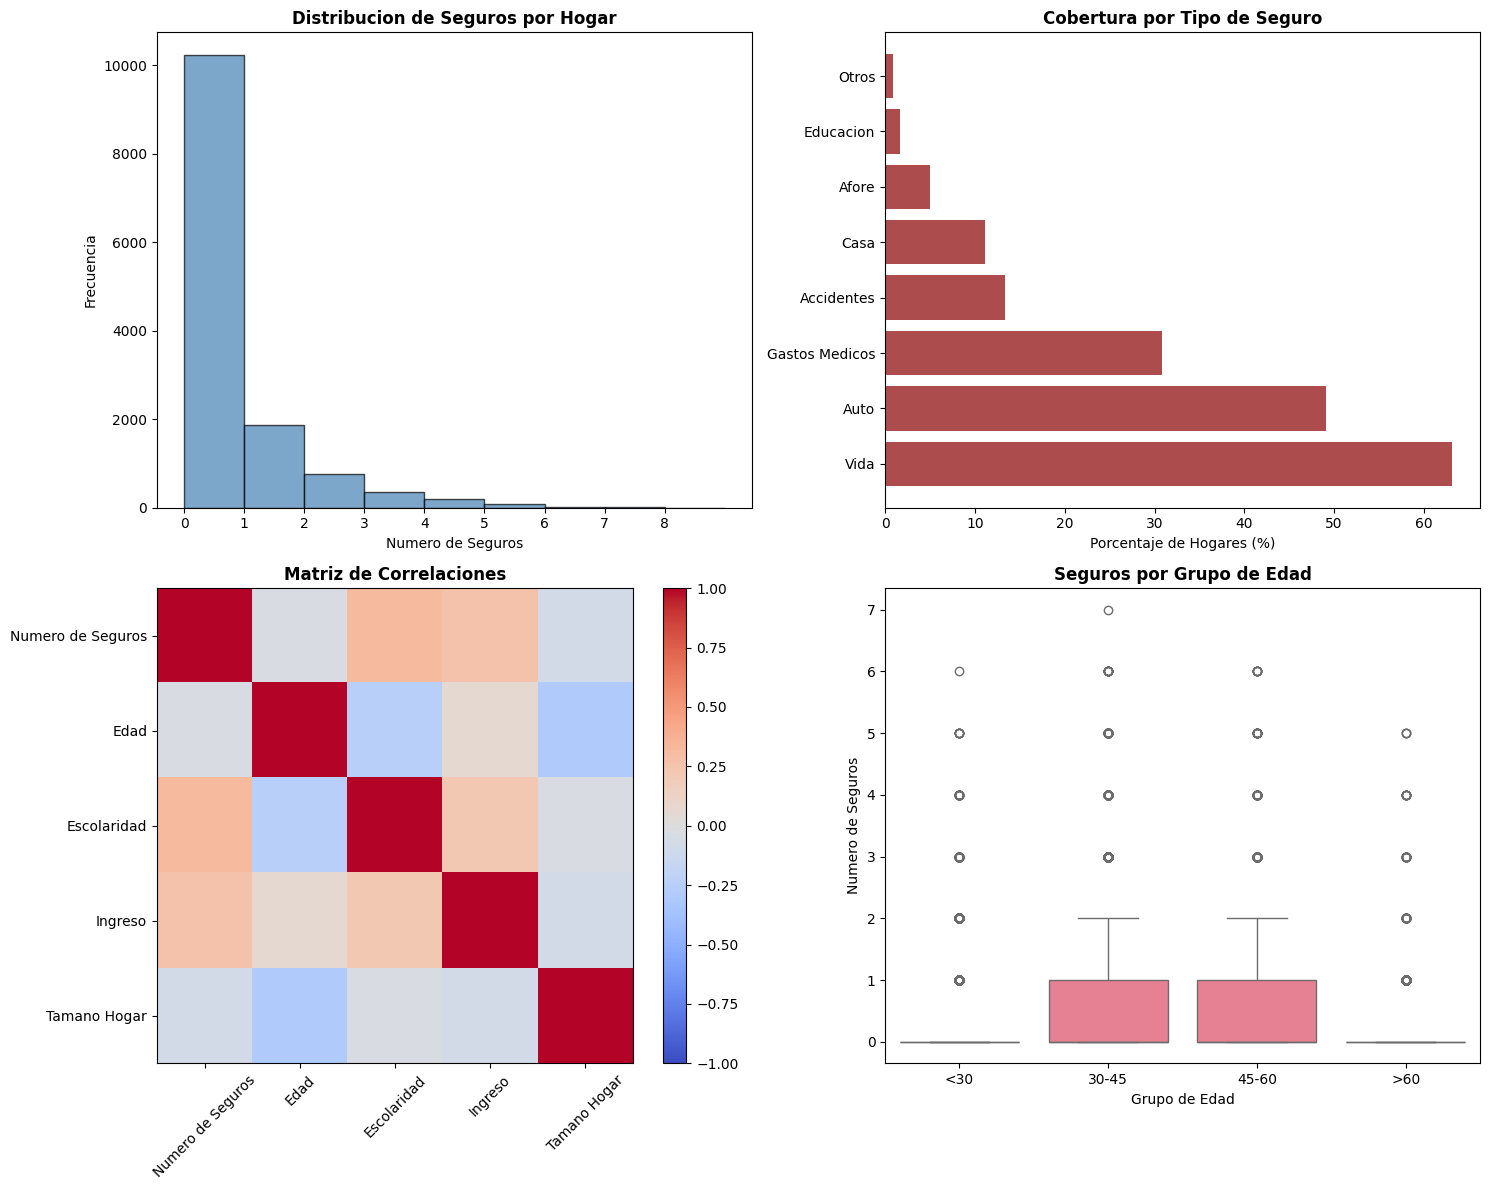


8. RESUMEN PARA INFORME

ANALISIS DESCRIPTIVO COMPLETADO:

DIVERSIFICACION DE SEGUROS:
- Los hogares poseen en promedio 0.42 seguros
- 75.8% de los hogares no tiene seguros
- Solo 10.3% tiene 2 o mas seguros

COBERTURA POR TIPO:
- Seguro mas comun: Vida (63.09%)
- Seguro menos comun: Otros (0.89%)

RELACIONES PRINCIPALES:
- La variable que mas correlaciona con numero de seguros es: Escolaridad (r = 0.314)

Analisis descriptivo y multivariado completado exitosamente


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import requests
import zipfile
import io
import time
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
import warnings
warnings.filterwarnings('ignore')

# Configurar visualizaciones
plt.style.use('default')
sns.set_palette("husl")

print("=== ANALISIS DESCRIPTIVO Y MULTIVARIADO - SEGUROS ===")

def descargar_enif_inteligente():
    url = "https://www.inegi.org.mx/contenidos/programas/enif/2024/microdatos/enif_2024_bd_csv.zip"


    # Crear sesión más realista
    session = requests.Session()

    # Headers completos de un navegador real
    headers = {
        'User-Agent': 'Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.114 Safari/537.36',
        'Accept': 'text/html,application/xhtml+xml,application/xml;q=0.9,image/webp,*/*;q=0.8',
        'Accept-Language': 'es-MX,es;q=0.9,en;q=0.8',
        'Accept-Encoding': 'gzip, deflate, br',
        'DNT': '1',
        'Connection': 'keep-alive',
        'Upgrade-Insecure-Requests': '1',
        'Sec-Fetch-Dest': 'document',
        'Sec-Fetch-Mode': 'navigate',
        'Sec-Fetch-Site': 'none',
        'Cache-Control': 'max-age=0',
    }

    try:
        print(" Haciendo pre-request para simular navegador...")
        time.sleep(2)

        # Primero hacer un HEAD request para verificar
        head_response = session.head(url, headers=headers, timeout=30, allow_redirects=True)
        print(f"Estado del servidor: {head_response.status_code}")

        if head_response.status_code == 200:
            print("Servidor responde, procediendo con descarga...")

            # Descarga con chunking para archivos grandes
            response = session.get(url, headers=headers, timeout=120, stream=True)
            response.raise_for_status()

            # Leer en chunks para manejar archivos grandes
            content = b""
            total_size = int(response.headers.get('content-length', 0))

            if total_size > 0:
                print(f" Descargando {total_size / (1024*1024):.1f} MB...")

                chunk_size = 8192
                for chunk in response.iter_content(chunk_size=chunk_size):
                    if chunk:
                        content += chunk

                print(" Descarga completada!")
                return content
            else:
                # Si no tenemos content-length, leer directamente
                content = response.content
                print(f" Descarga completada: {len(content) / (1024*1024):.1f} MB")
                return content

        else:
            print(f" Servidor no disponible: {head_response.status_code}")

    except Exception as e:
        print(f" Error en descarga: {e}")

    return None

print(" INICIANDO WEB SCRAPING DEL INEGI...")
datos_zip = descargar_enif_inteligente()

if datos_zip is not None:
    print(" Procesando archivo ZIP descargado...")

    try:
        with zipfile.ZipFile(io.BytesIO(datos_zip)) as archivo_zip:
            # Verificar contenido
            archivos = archivo_zip.namelist()
            print(" Contenido del ZIP:")
            for archivo in archivos:
                print(f"    {archivo}")

            # CARGAR TMODULO.CSV
            print("\n Cargando TMODULO.csv...")
            with archivo_zip.open('TMODULO.csv') as archivo:
                df = pd.read_csv(archivo, encoding='latin-1', low_memory=False)
            print(f"TMODULO cargado: {len(df):,} registros, {df.shape[1]} columnas")

            # CARGAR TVIVIENDA.CSV
            print(" Cargando TVIVIENDA.csv...")
            with archivo_zip.open('TVIVIENDA.csv') as archivo:
                df_vivienda = pd.read_csv(archivo, encoding='latin-1', low_memory=False)
            print(f" TVIVIENDA cargado: {len(df_vivienda):,} registros, {df_vivienda.shape[1]} columnas")

    except Exception as e:
        print(f" Error procesando ZIP: {e}")
        exit()
else:
    # ULTIMO INTENTO: método directo con !wget
    print(" Último intento con método directo...")
    try:
        !wget --no-check-certificate --timeout=120 -O enif_direct.zip "https://www.inegi.org.mx/contenidos/programas/enif/2024/microdatos/enif_2024_bd_csv.zip"

        with zipfile.ZipFile('enif_direct.zip', 'r') as archivo_zip:
            df = pd.read_csv(archivo_zip.open('TMODULO.csv'), encoding='latin-1', low_memory=False)
            df_vivienda = pd.read_csv(archivo_zip.open('TVIVIENDA.csv'), encoding='latin-1', low_memory=False)
        print(" Descarga exitosa con método directo!")

    except Exception as e:
        print(f"Todos los métodos fallaron: {e}")
        print(" Posibles soluciones:")
        print("   1. El servidor del INEGI puede estar caído temporalmente")
        print("   2. Puede haber restricciones de red en Colab")
        print("   3. Intenta ejecutar de nuevo en 5-10 minutos")
        exit()

# CONTINÚA CON EL RESTO DE TU CÓDIGO ORIGINAL...
print(f"\n WEB SCRAPING EXITOSO!")
print(f" Resumen de datos cargados:")
print(f"   • TMODULO: {len(df):,} registros")
print(f"   • TVIVIENDA: {len(df_vivienda):,} registros")

#===================================



# (combinando con la base de vivienda df_vivienda con df que tiene los datos del seguro, para obtener tamaño del hogar)
df = df.merge(df_vivienda[['LLAVEVIV', 'P1_1']], on='LLAVEVIV', how='left')
df['tamano_hogar'] = pd.to_numeric(df['P1_1'], errors='coerce') #pd.to_numeric() Convierte texto/caracteres a números, errors='coerce'Si encuentra un valor que NO se puede convertir a número, lo cambia a NaN (valor faltante)

print("Variables cargadas correctamente")

# 1. CREAR VARIABLE DE DIVERSIFICACION DE SEGUROS
print("\n" + "="*60) #Crear una línea de 60 signos "=" seguidos
print("1. CREACION DE VARIABLE DE DIVERSIFICACION DE SEGUROS")
print("="*60)

seguros_columns = ['P8_5_1', 'P8_5_2', 'P8_5_3', 'P8_5_4', 'P8_5_5', 'P8_5_6', 'P8_5_7', 'P8_5_8']
nombres_seguros = ['Vida', 'Gastos Medicos', 'Auto', 'Accidentes', 'Casa', 'Educacion', 'Afore', 'Otros']

for col in seguros_columns:
    df[f'{col}_num'] = (df[col] == 1).astype(int)


    #df[col] accede a la columna original del seguro.
    #== 1 compara si el valor es igual a 1 (que significa "Sí" tiene el seguro)
    #Esto devuelve True si tiene el seguro, False si no lo tiene2. .astype(int)
    #Convierte True a 1 y False a 0
    #De texto/booleanos a números que podemos sumar
    #3. df[f'{col}_num'] =
    #Crea una nueva columna con el nombre original + "_num"

df['num_seguros'] = df[[f'{col}_num' for col in seguros_columns]].sum(axis=1)

print(f"Variable creada: num_seguros")
print(f"Rango observado: {df['num_seguros'].min()} a {df['num_seguros'].max()} seguros")
print(f"Rango teorico: 0 a 8 seguros")

# 2. ANALISIS DE COBERTURA POR TIPO DE SEGURO
print("\n" + "="*60)
print("2. COBERTURA POR TIPO DE SEGURO")
print("="*60)

resultados_cobertura = []

for i, col in enumerate(seguros_columns):
    total = df[col].notna().sum()
    si = (df[col] == 1).sum()
    no = (df[col] == 2).sum()
    blanco = df[col].isna().sum()
    cobertura = (si / total) * 100 if total > 0 else 0

    resultados_cobertura.append({
        'Tipo_Seguro': nombres_seguros[i],
        'Si': si,
        'No': no,
        'Blanco_Secuencia': blanco,
        'Cobertura_%': round(cobertura, 2)
    })

resultados_cobertura_df = pd.DataFrame(resultados_cobertura)
resultados_cobertura_df['Ranking'] = resultados_cobertura_df['Cobertura_%'].rank(ascending=False)
resultados_cobertura_df = resultados_cobertura_df.sort_values('Ranking')

print(resultados_cobertura_df.to_string(index=False))#index=False OMITE los números de fila (0, 1, 2, 3...) Muestra solo los datos, sin la columna de índice

# 3. ANALISIS DESCRIPTIVO DE VARIABLES SOCIOECONOMICAS
print("\n" + "="*60)
print("3. ESTADISTICOS DESCRIPTIVOS - VARIABLES SOCIOECONOMICAS")
print("="*60)

# Definir variables socioeconomicas (ajustar nombres si es necesario)
variables_socioeconomicas = {
    'num_seguros': 'Numero de Seguros',
    'EDAD_V': 'Edad',
    'NIV': 'Escolaridad',
    'P3_11A': 'Ingreso',
    'tamano_hogar': 'Tamano Hogar'
}

# Crear dataset para analisis
df_analisis = df[list(variables_socioeconomicas.keys())].copy()#El .copy() crea una copia independiente del DataFrame original.

# Verificar y limpiar variables
df_analisis['EDAD_V'] = pd.to_numeric(df_analisis['EDAD_V'], errors='coerce')
df_analisis['NIV'] = pd.to_numeric(df_analisis['NIV'], errors='coerce')
df_analisis['P3_11A'] = pd.to_numeric(df_analisis['P3_11A'], errors='coerce')

print("Resumen estadistico de variables:")
print(df_analisis.describe().round(3))

# Estadisticas detalladas por variable
print("\n--- ESTADISTICAS DETALLADAS ---")
for var, nombre in variables_socioeconomicas.items():
    if var in df_analisis.columns:
        data = df_analisis[var].dropna()
        print(f"\n{nombre} ({var}):")
        print(f"  Media: {data.mean():.2f}")
        print(f"  Mediana: {data.median():.2f}")
        print(f"  Desviacion: {data.std():.2f}")
        print(f"  Min: {data.min()}, Max: {data.max()}")
        print(f"  No nulos: {len(data):,}")#LONGITUD

# 4. DISTRIBUCION DE LA VARIABLE PRINCIPAL
print("\n" + "="*60)
print("4. DISTRIBUCION DE NUMERO DE SEGUROS")
print("="*60)

distribucion = df_analisis['num_seguros'].value_counts().sort_index()#sort_index() ORDENA LOS RESULTADOS por el número de seguros (0,1,2,3...10000) en lugar de por frecuencia.


porcentajes = (distribucion / len(df_analisis)) * 100
acumulado = porcentajes.cumsum()

tabla_distribucion = pd.DataFrame({
    'Num_Seguros': distribucion.index,
    'Frecuencia': distribucion.values,
    'Porcentaje': porcentajes.round(2),
    'Acumulado': acumulado.round(2)#REDONDEA a dos decimales por ser un porcentaje
})

print(tabla_distribucion.to_string(index=False))#PARA ENTENDER LA DISTRIBUCIÓN REAL, concentraciones

# Estadisticas clave
print(f"\nHogares sin seguros: {(df_analisis['num_seguros'] == 0).sum():,} ({(df_analisis['num_seguros'] == 0).mean() * 100:.1f}%)")
print(f"Hogares con 1 seguro: {(df_analisis['num_seguros'] == 1).sum():,} ({(df_analisis['num_seguros'] == 1).mean() * 100:.1f}%)")
print(f"Hogares con 2+ seguros: {(df_analisis['num_seguros'] >= 2).sum():,} ({(df_analisis['num_seguros'] >= 2).mean() * 100:.1f}%)")
print(f"Hogares con 3+ seguros: {(df_analisis['num_seguros'] >= 3).sum():,} ({(df_analisis['num_seguros'] >= 3).mean() * 100:.1f}%)")

# 5. ANALISIS MULTIVARIADO - CORRELACIONES
print("\n" + "="*60)
print("5. ANALISIS MULTIVARIADO - MATRIZ DE CORRELACIONES")
print("="*60)

correlaciones = df_analisis.corr()
print("Matriz de correlaciones:")
print(correlaciones.round(3))

# Correlacion con numero de seguros
print("\nCorrelaciones con Numero de Seguros:")
corr_seguros = correlaciones['num_seguros'].sort_values(ascending=False)
for var, corr in corr_seguros.items():
    if var != 'num_seguros':
        nombre = variables_socioeconomicas.get(var, var)
        print(f"  {nombre}: {corr:.3f}")

# 6. ANALISIS MULTIVARIADO - COMPONENTES PRINCIPALES
print("\n" + "="*60)
print("6. ANALISIS DE COMPONENTES PRINCIPALES (PCA)")
print("="*60)

# Preparar datos para PCA (excluir num_seguros como variable objetivo)
variables_pca = ['EDAD_V', 'NIV', 'P3_11A', 'tamano_hogar'] #Selecciona SOLO las variables independientes para el PCA


df_pca = df_analisis[variables_pca].dropna() #Resultado: DataFrame con solo registros completos para PCA
#Elimina TODAS las filas que tengan al menos un NaN en cualquiera de estas 4 variables
if len(df_pca) > 0: #Verifica que queden datos después de eliminar NaN
    # Estandarizar
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(df_pca)#ESTANDARIZA las variables (paso CRÍTICO para PCA)
    #Todas las variables tienen misma escala

    #PCA trata todas por igual


    # Aplicar PCA
    pca = PCA()
    pca_result = pca.fit_transform(X_scaled)

    # Resultados
    var_explicada = pca.explained_variance_ratio_ # ← ESTO son los eigenvalores en porcentaje
    var_acumulada = np.cumsum(var_explicada)

    print("Varianza explicada por componente:")
    for i, (var, acum) in enumerate(zip(var_explicada, var_acumulada)):
        print(f"  Componente {i+1}: {var*100:.1f}% (Acumulado: {acum*100:.1f}%)")

    # Contribucion de variables
    print("\nContribucion de variables a componentes:")
    contribuciones = pd.DataFrame(
        pca.components_.T,
        columns=[f'PC{i+1}' for i in range(pca.n_components_)],
        index=variables_pca
    ).round(3)
    print(contribuciones)

else:
    print("No hay datos suficientes para PCA")

# 7. VISUALIZACIONES
print("\n" + "="*60)
print("7. GENERANDO VISUALIZACIONES")
print("="*60)

# Figura con subplots
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 7.1 Histograma de numero de seguros
axes[0,0].hist(df_analisis['num_seguros'], bins=range(0, 10), alpha=0.7, color='steelblue', edgecolor='black')
axes[0,0].set_title('Distribucion de Seguros por Hogar', fontweight='bold')
axes[0,0].set_xlabel('Numero de Seguros')
axes[0,0].set_ylabel('Frecuencia')
axes[0,0].set_xticks(range(0, 9))

# 7.2 Cobertura por tipo de seguro
axes[0,1].barh(resultados_cobertura_df['Tipo_Seguro'], resultados_cobertura_df['Cobertura_%'], color='darkred', alpha=0.7)
axes[0,1].set_title('Cobertura por Tipo de Seguro', fontweight='bold')
axes[0,1].set_xlabel('Porcentaje de Hogares (%)')

# 7.3 Matriz de correlaciones
im = axes[1,0].imshow(correlaciones, cmap='coolwarm', aspect='auto', vmin=-1, vmax=1)
axes[1,0].set_title('Matriz de Correlaciones', fontweight='bold')
axes[1,0].set_xticks(range(len(correlaciones.columns)))
axes[1,0].set_yticks(range(len(correlaciones.columns)))
axes[1,0].set_xticklabels([variables_socioeconomicas.get(col, col) for col in correlaciones.columns], rotation=45)
axes[1,0].set_yticklabels([variables_socioeconomicas.get(col, col) for col in correlaciones.columns])
plt.colorbar(im, ax=axes[1,0])

# 7.4 Boxplot de seguros por edad
df_boxplot = df_analisis.dropna()
df_boxplot['grupo_edad'] = pd.cut(df_boxplot['EDAD_V'], bins=[0, 30, 45, 60, 100], labels=['<30', '30-45', '45-60', '>60'])
sns.boxplot(data=df_boxplot, x='grupo_edad', y='num_seguros', ax=axes[1,1])
axes[1,1].set_title('Seguros por Grupo de Edad', fontweight='bold')
axes[1,1].set_xlabel('Grupo de Edad')
axes[1,1].set_ylabel('Numero de Seguros')

plt.tight_layout()
plt.show()


# 8. RESUMEN PARA INFORME
print("\n" + "="*60)
print("8. RESUMEN PARA INFORME")
print("="*60)

print(f"""
ANALISIS DESCRIPTIVO COMPLETADO:

DIVERSIFICACION DE SEGUROS:
- Los hogares poseen en promedio {df_analisis['num_seguros'].mean():.2f} seguros
- {((df_analisis['num_seguros'] == 0).mean() * 100):.1f}% de los hogares no tiene seguros
- Solo {((df_analisis['num_seguros'] >= 2).mean() * 100):.1f}% tiene 2 o mas seguros

COBERTURA POR TIPO:
- Seguro mas comun: {resultados_cobertura_df.iloc[0]['Tipo_Seguro']} ({resultados_cobertura_df.iloc[0]['Cobertura_%']}%)
- Seguro menos comun: {resultados_cobertura_df.iloc[-1]['Tipo_Seguro']} ({resultados_cobertura_df.iloc[-1]['Cobertura_%']}%)

RELACIONES PRINCIPALES:
- La variable que mas correlaciona con numero de seguros es: {variables_socioeconomicas.get(corr_seguros.index[1], corr_seguros.index[1])} (r = {corr_seguros.iloc[1]:.3f})
""")

print("Analisis descriptivo y multivariado completado exitosamente")

# Análisis de valores reemplazados en la limpieza

In [ ]:
# VERIFICAR CUÁNTOS VALORES SE CONVIRTIERON A NaN
print("\n=== VERIFICACIÓN DE CONVERSIÓN A NaN ===")

variables_convertidas = ['EDAD_V', 'NIV', 'P3_11A', 'tamano_hogar']
for variable in variables_convertidas:
    if variable in df_analisis.columns:
        nan_count = df_analisis[variable].isna().sum()
        total_count = len(df_analisis[variable])
        porcentaje_nan = (nan_count / total_count) * 100
        print(f"{variable}: {nan_count:,} NaN de {total_count:,} ({porcentaje_nan:.2f}%)")


=== VERIFICACIÓN DE CONVERSIÓN A NaN ===
EDAD_V: 0 NaN de 13,502 (0.00%)
NIV: 0 NaN de 13,502 (0.00%)
P3_11A: 4,134 NaN de 13,502 (30.62%)
tamano_hogar: 0 NaN de 13,502 (0.00%)


Pero todos esos reemplazados fueron valores vacios en el excel,entonces leyó correctamente todo

# Estimación de Parámetros e Interpretación de los Resultados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import warnings
import statsmodels.api as sm
import statsmodels.formula.api as smf
import statsmodels.stats.api as sms

# Cargar datos principales
df = pd.read_csv(
    "TMODULO.csv",
    encoding='latin-1',
    low_memory=False
)

# Cargar datos de vivienda para tamaño del hogar
df_vivienda = pd.read_csv(
    "TVIVIENDA.csv",
    encoding='latin-1',
    low_memory=False
)

print(f"Registros TMODULO: {len(df):,}")
print(f"Registros TVIVIENDA: {len(df_vivienda):,}")

# (combinando con la base de vivienda df_vivienda con df que tiene los datos del seguro, para obtener tamaño del hogar)
df = df.merge(df_vivienda[['LLAVEVIV', 'P1_1']], on='LLAVEVIV', how='left')
df['tamano_hogar'] = pd.to_numeric(df['P1_1'], errors='coerce')

print("Variables cargadas correctamente")

# 1. CREAR VARIABLE DE DIVERSIFICACION DE SEGUROS
print("\n" + "="*60) #Crear una línea de 60 signos "=" seguidos
print("1. CREACION DE VARIABLE DE DIVERSIFICACION DE SEGUROS")
print("="*60)

seguros_columns = ['P8_5_1', 'P8_5_2', 'P8_5_3', 'P8_5_4', 'P8_5_5', 'P8_5_6', 'P8_5_7', 'P8_5_8']
nombres_seguros = ['Vida', 'Gastos Medicos', 'Auto', 'Accidentes', 'Casa', 'Educacion', 'Afore', 'Otros']

for col in seguros_columns:
    df[f'{col}_num'] = (df[col] == 1).astype(int)


    #df[col] accede a la columna original del seguro.
    #== 1 compara si el valor es igual a 1 (que significa "Sí" tiene el seguro)
    #Esto devuelve True si tiene el seguro, False si no lo tiene2. .astype(int)
    #Convierte True a 1 y False a 0
    #De texto/booleanos a números que podemos sumar
    #3. df[f'{col}_num'] =
    #Crea una nueva columna con el nombre original + "_num"

df['num_seguros'] = df[[f'{col}_num' for col in seguros_columns]].sum(axis=1)

print(f"Variable creada: num_seguros")
print(f"Rango observado: {df['num_seguros'].min()} a {df['num_seguros'].max()} seguros")
print(f"Rango teorico: 0 a 8 seguros")

# 2. ANALISIS DE COBERTURA POR TIPO DE SEGURO
print("\n" + "="*60)
print("2. COBERTURA POR TIPO DE SEGURO")
print("="*60)

resultados_cobertura = []

for i, col in enumerate(seguros_columns):
    total = df[col].notna().sum()
    si = (df[col] == 1).sum()
    no = (df[col] == 2).sum()
    blanco = df[col].isna().sum()
    cobertura = (si / total) * 100 if total > 0 else 0

    resultados_cobertura.append({
        'Tipo_Seguro': nombres_seguros[i],
        'Si': si,
        'No': no,
        'Blanco_Secuencia': blanco,
        'Cobertura_%': round(cobertura, 2)
    })

resultados_cobertura_df = pd.DataFrame(resultados_cobertura)
resultados_cobertura_df['Ranking'] = resultados_cobertura_df['Cobertura_%'].rank(ascending=False)
resultados_cobertura_df = resultados_cobertura_df.sort_values('Ranking')

print(resultados_cobertura_df.to_string(index=False))

# Definir variables socioeconomicas
variables_socioeconomicas = {
    'num_seguros': 'Numero de Seguros',
    'EDAD_V': 'Edad',
    'NIV': 'Escolaridad',
    'P3_11A': 'Ingreso',
    'tamano_hogar': 'Tamano Hogar'
}

# Crear dataset para analisis
df_analisis = df[list(variables_socioeconomicas.keys())].copy()

# Verificar y limpiar variables
df_analisis['EDAD_V'] = pd.to_numeric(df_analisis['EDAD_V'], errors='coerce')
df_analisis['NIV'] = pd.to_numeric(df_analisis['NIV'], errors='coerce')
df_analisis['P3_11A'] = pd.to_numeric(df_analisis['P3_11A'], errors='coerce')






#///////////////////////////////////////////////////////////////////////////////////#
print("\n" + "="*60)
print("9. MODELO DE REGRESIÓN LINEAL MÚLTIPLE")
print("="*60)

# 1. Preparación de los datos
# Variables: num_seguros (Y), EDAD_V, NIV, P3_11A, tamano_hogar (X)

vars_modelo = ['num_seguros', 'EDAD_V', 'NIV', 'P3_11A', 'tamano_hogar']
df_regresion = df_analisis[vars_modelo].dropna()

print(f"Registros válidos para el modelo: {len(df_regresion):,}")

# 2. Definir X (Independientes) y Y (Dependiente)
X = df_regresion[['EDAD_V', 'NIV', 'P3_11A', 'tamano_hogar']]
y = df_regresion['num_seguros']

# 3. Añadir la constante (Intercepto / Beta 0)
# Statsmodels no agrega el intercepto por defecto, hay que añadirlo manualmente
X = sm.add_constant(X)

# 4. Ajustar el modelo (OLS - Ordinary Least Squares)
modelo = sm.OLS(y, X).fit()

# 5. Imprimir resultados
print(modelo.summary())


# --- INTERPRETACIÓN AUTOMÁTICA BÁSICA ---
print("\n--- Interpretación de Coeficientes (Betas) ---")
params = modelo.params
pvalues = modelo.pvalues

nombres_vars = {
    'const': 'Intercepto (Beta 0)',
    'EDAD_V': 'Edad (Beta 1)',
    'NIV': 'Escolaridad (Beta 2)',
    'P3_11A': 'Ingreso (Beta 3)',
    'tamano_hogar': 'Tam. Hogar (Beta 4)'
}

for var in params.index:
    nombre_real = nombres_vars.get(var, var)
    coef = params[var]
    pval = pvalues[var]
    sig = ""

    if pval < 0.01: sig = "*** (Altamente Signif.)"
    elif pval < 0.05: sig = "** (Significativo)"
    elif pval < 0.1: sig = "* (Poco Signif.)"
    else: sig = "(No Significativo)"

    print(f"{nombre_real:<20} | Coef: {coef:>10.5f} | P-value: {pval:.4f} {sig}")

print(f"\nR-cuadrado: {modelo.rsquared:.4f} (El modelo explica el {modelo.rsquared*100:.2f}% de la varianza)")


Registros TMODULO: 4,284
Registros TVIVIENDA: 13,303
Variables cargadas correctamente

1. CREACION DE VARIABLE DE DIVERSIFICACION DE SEGUROS
Variable creada: num_seguros
Rango observado: 0 a 6 seguros
Rango teorico: 0 a 8 seguros

2. COBERTURA POR TIPO DE SEGURO
   Tipo_Seguro  Si   No  Blanco_Secuencia  Cobertura_%  Ranking
          Vida 637  386              3261        62.27      1.0
          Auto 505  518              3261        49.36      2.0
Gastos Medicos 315  708              3261        30.79      3.0
    Accidentes 144  879              3261        14.08      4.0
          Casa 123  900              3261        12.02      5.0
         Afore  63  960              3261         6.16      6.0
     Educacion  13 1010              3261         1.27      7.0
         Otros   9 1014              3261         0.88      8.0

9. MODELO DE REGRESIÓN LINEAL MÚLTIPLE
Registros válidos para el modelo: 2,987
                            OLS Regression Results                            
De

In [ ]:
print(df_regresion['num_seguros'].mean(), df_regresion['num_seguros'].var())

0.5212587880816874 1.0433355883981306


# **DIAGNOSTICO DEL MODELO**

1.   Elemento de la lista

1.   Elemento de la lista
2.   Elemento de la lista


2.   Elemento de la lista





In [ ]:
import statsmodels
import statsmodels.formula.api as smf
import pandas as pd

In [ ]:
# base code
import numpy as np
import seaborn as sns
from statsmodels.tools.tools import maybe_unwrap_results
from statsmodels.graphics.gofplots import ProbPlot
from statsmodels.stats.outliers_influence import variance_inflation_factor
import matplotlib.pyplot as plt
from typing import Type

style_talk = 'seaborn-talk'    #refer to plt.style.available

class LinearRegDiagnostic():
    """
    Diagnostic plots to identify potential problems in a linear regression fit.
    Mainly,
        a. non-linearity of data
        b. Correlation of error terms
        c. non-constant variance
        d. outliers
        e. high-leverage points
        f. collinearity

    Authors:
        Prajwal Kafle (p33ajkafle@gmail.com, where 3 = r)
        Does not come with any sort of warranty.
        Please test the code one your end before using.

        Matt Spinelli (m3spinelli@gmail.com, where 3 = r)
        (1) Fixed incorrect annotation of the top most extreme residuals in
            the Residuals vs Fitted and, especially, the Normal Q-Q plots.
        (2) Changed Residuals vs Leverage plot to match closer the y-axis
            range shown in the equivalent plot in the R package ggfortify.
        (3) Added horizontal line at y=0 in Residuals vs Leverage plot to
            match the plots in R package ggfortify and base R.
        (4) Added option for placing a vertical guideline on the Residuals
            vs Leverage plot using the rule of thumb of h = 2p/n to denote
            high leverage (high_leverage_threshold=True).
        (5) Added two more ways to compute the Cook's Distance (D) threshold:
            * 'baseR': D > 1 and D > 0.5 (default)
            * 'convention': D > 4/n
            * 'dof': D > 4 / (n - k - 1)
        (6) Fixed class name to conform to Pascal casing convention
        (7) Fixed Residuals vs Leverage legend to work with loc='best'
    """

    def __init__(self,
                 results: Type[statsmodels.regression.linear_model.RegressionResultsWrapper]) -> None:
        """
        For a linear regression model, generates following diagnostic plots:

        a. residual
        b. qq
        c. scale location and
        d. leverage

        and a table

        e. vif

        Args:
            results (Type[statsmodels.regression.linear_model.RegressionResultsWrapper]):
                must be instance of statsmodels.regression.linear_model object

        Raises:
            TypeError: if instance does not belong to above object

        Example:
        >>> import numpy as np
        >>> import pandas as pd
        >>> import statsmodels.formula.api as smf
        >>> x = np.linspace(-np.pi, np.pi, 100)
        >>> y = 3*x + 8 + np.random.normal(0,1, 100)
        >>> df = pd.DataFrame({'x':x, 'y':y})
        >>> res = smf.ols(formula= "y ~ x", data=df).fit()
        >>> cls = Linear_Reg_Diagnostic(res)
        >>> cls(plot_context="seaborn-v0_8-paper")

        In case you do not need all plots you can also independently make an individual plot/table
        in following ways

        >>> cls = Linear_Reg_Diagnostic(res)
        >>> cls.residual_plot()
        >>> cls.qq_plot()
        >>> cls.scale_location_plot()
        >>> cls.leverage_plot()
        >>> cls.vif_table()
        """

        if isinstance(results, statsmodels.regression.linear_model.RegressionResultsWrapper) is False:
            raise TypeError("result must be instance of statsmodels.regression.linear_model.RegressionResultsWrapper object")

        self.results = maybe_unwrap_results(results)

        self.y_true = self.results.model.endog
        self.y_predict = self.results.fittedvalues
        self.xvar = self.results.model.exog
        self.xvar_names = self.results.model.exog_names

        self.residual = np.array(self.results.resid)
        influence = self.results.get_influence()
        self.residual_norm = influence.resid_studentized_internal
        self.leverage = influence.hat_matrix_diag
        self.cooks_distance = influence.cooks_distance[0]
        self.nparams = len(self.results.params)
        self.nresids = len(self.residual_norm)

    def __call__(self, plot_context='seaborn-v0_8-paper', **kwargs):
        # print(plt.style.available)
        with plt.style.context(plot_context):
            fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(10,10))
            self.residual_plot(ax=ax[0,0])
            self.qq_plot(ax=ax[0,1])
            self.scale_location_plot(ax=ax[1,0])
            self.leverage_plot(
                ax=ax[1,1],
                high_leverage_threshold = kwargs.get('high_leverage_threshold'),
                cooks_threshold = kwargs.get('cooks_threshold'))
            plt.show()

        return self.vif_table(), fig, ax,

    def residual_plot(self, ax=None):
        """
        Residual vs Fitted Plot

        Graphical tool to identify non-linearity.
        (Roughly) Horizontal red line is an indicator that the residual has a linear pattern
        """
        if ax is None:
            fig, ax = plt.subplots()

        sns.residplot(
            x=self.y_predict,
            y=self.residual,
            lowess=True,
            scatter_kws={'alpha': 0.5},
            line_kws={'color': 'red', 'lw': 1, 'alpha': 0.8},
            ax=ax)

        # annotations
        residual_abs = np.abs(self.residual)
        abs_resid = np.flip(np.argsort(residual_abs), 0)
        abs_resid_top_3 = abs_resid[:3]
        for i in abs_resid_top_3:
            ax.annotate(
                i,
                xy=(self.y_predict[i], self.residual[i]),
                color='C3')

        ax.set_title('Residuals vs Fitted', fontweight="bold")
        ax.set_xlabel('Fitted values')
        ax.set_ylabel('Residuals')
        return ax

    def qq_plot(self, ax=None):
        """
        Standarized Residual vs Theoretical Quantile plot

        Used to visually check if residuals are normally distributed.
        Points spread along the diagonal line will suggest so.
        """
        if ax is None:
            fig, ax = plt.subplots()

        QQ = ProbPlot(self.residual_norm)
        fig = QQ.qqplot(line='45', alpha=0.5, lw=1, ax=ax)

        # annotations
        abs_norm_resid = np.flip(np.argsort(np.abs(self.residual_norm)), 0)
        abs_norm_resid_top_3 = abs_norm_resid[:3]
        for i, x, y in self.__qq_top_resid(QQ.theoretical_quantiles, abs_norm_resid_top_3):
            ax.annotate(
                i,
                xy=(x, y),
                ha='right',
                color='C3')

        ax.set_title('Normal Q-Q', fontweight="bold")
        ax.set_xlabel('Theoretical Quantiles')
        ax.set_ylabel('Standardized Residuals')
        return ax

    def scale_location_plot(self, ax=None):
        """
        Sqrt(Standarized Residual) vs Fitted values plot

        Used to check homoscedasticity of the residuals.
        Horizontal line will suggest so.
        """
        if ax is None:
            fig, ax = plt.subplots()

        residual_norm_abs_sqrt = np.sqrt(np.abs(self.residual_norm))

        ax.scatter(self.y_predict, residual_norm_abs_sqrt, alpha=0.5);
        sns.regplot(
            x=self.y_predict,
            y=residual_norm_abs_sqrt,
            scatter=False, ci=False,
            lowess=True,
            line_kws={'color': 'red', 'lw': 1, 'alpha': 0.8},
            ax=ax)

        # annotations
        abs_sq_norm_resid = np.flip(np.argsort(residual_norm_abs_sqrt), 0)
        abs_sq_norm_resid_top_3 = abs_sq_norm_resid[:3]
        for i in abs_sq_norm_resid_top_3:
            ax.annotate(
                i,
                xy=(self.y_predict[i], residual_norm_abs_sqrt[i]),
                color='C3')

        ax.set_title('Scale-Location', fontweight="bold")
        ax.set_xlabel('Fitted values')
        ax.set_ylabel(r'$\sqrt{|\mathrm{Standardized\ Residuals}|}$');
        return ax

    def leverage_plot(self, ax=None, high_leverage_threshold=False, cooks_threshold='baseR'):
        """
        Residual vs Leverage plot

        Points falling outside Cook's distance curves are considered observation that can sway the fit
        aka are influential.
        Good to have none outside the curves.
        """
        if ax is None:
            fig, ax = plt.subplots()

        ax.scatter(
            self.leverage,
            self.residual_norm,
            alpha=0.5);

        sns.regplot(
            x=self.leverage,
            y=self.residual_norm,
            scatter=False,
            ci=False,
            lowess=True,
            line_kws={'color': 'red', 'lw': 1, 'alpha': 0.8},
            ax=ax)

        # annotations
        leverage_top_3 = np.flip(np.argsort(self.cooks_distance), 0)[:3]
        for i in leverage_top_3:
            ax.annotate(
                i,
                xy=(self.leverage[i], self.residual_norm[i]),
                color = 'C3')

        factors = []
        if cooks_threshold == 'baseR' or cooks_threshold is None:
            factors = [1, 0.5]
        elif cooks_threshold == 'convention':
            factors = [4/self.nresids]
        elif cooks_threshold == 'dof':
            factors = [4/ (self.nresids - self.nparams)]
        else:
            raise ValueError("threshold_method must be one of the following: 'convention', 'dof', or 'baseR' (default)")
        for i, factor in enumerate(factors):
            label = "Cook's distance" if i == 0 else None
            xtemp, ytemp = self.__cooks_dist_line(factor)
            ax.plot(xtemp, ytemp, label=label, lw=1.25, ls='--', color='red')
            ax.plot(xtemp, np.negative(ytemp), lw=1.25, ls='--', color='red')

        if high_leverage_threshold:
            high_leverage = 2 * self.nparams / self.nresids
            if max(self.leverage) > high_leverage:
                ax.axvline(high_leverage, label='High leverage', ls='-.', color='purple', lw=1)

        ax.axhline(0, ls='dotted', color='black', lw=1.25)
        ax.set_xlim(0, max(self.leverage)+0.01)
        ax.set_ylim(min(self.residual_norm)-0.1, max(self.residual_norm)+0.1)
        ax.set_title('Residuals vs Leverage', fontweight="bold")
        ax.set_xlabel('Leverage')
        ax.set_ylabel('Standardized Residuals')
        plt.legend(loc='best')
        return ax

    def vif_table(self):
        """
        VIF table

        VIF, the variance inflation factor, is a measure of multicollinearity.
        VIF > 5 for a variable indicates that it is highly collinear with the
        other input variables.
        """
        vif_df = pd.DataFrame()
        vif_df["Features"] = self.xvar_names
        vif_df["VIF Factor"] = [variance_inflation_factor(self.xvar, i) for i in range(self.xvar.shape[1])]

        return (vif_df
                .sort_values("VIF Factor")
                .round(2))


    def __cooks_dist_line(self, factor):
        """
        Helper function for plotting Cook's distance curves
        """
        p = self.nparams
        formula = lambda x: np.sqrt((factor * p * (1 - x)) / x)
        x = np.linspace(0.001, max(self.leverage), 50)
        y = formula(x)
        return x, y


    def __qq_top_resid(self, quantiles, top_residual_indices):
        """
        Helper generator function yielding the index and coordinates
        """
        offset = 0
        quant_index = 0
        previous_is_negative = None
        for resid_index in top_residual_indices:
            y = self.residual_norm[resid_index]
            is_negative = y < 0
            if previous_is_negative == None or previous_is_negative == is_negative:
                offset += 1
            else:
                quant_index -= offset
            x = quantiles[quant_index] if is_negative else np.flip(quantiles, 0)[quant_index]
            quant_index += 1
            previous_is_negative = is_negative
            yield resid_index, x, y


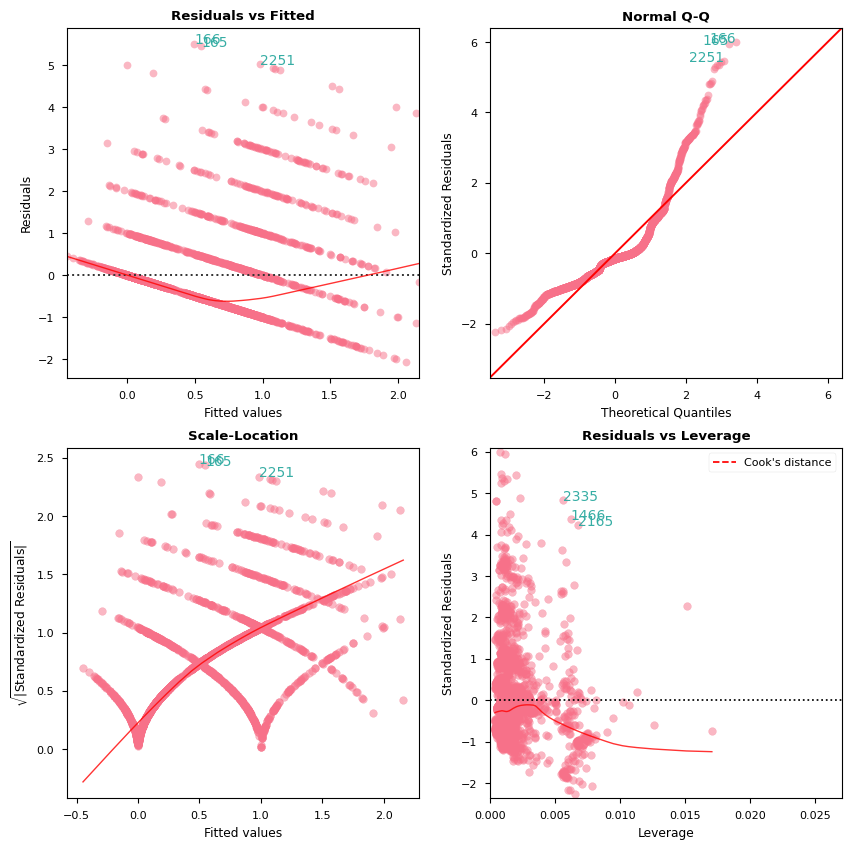

       Features  VIF Factor
4  tamano_hogar        1.08
3        P3_11A        1.08
1        EDAD_V        1.17
2           NIV        1.21
0         const       29.02


In [ ]:
# Alternatively, all diagnostics can be generated in one go as follows.
# Fig and ax can be used to modify axes or plot properties after the fact.
cls = LinearRegDiagnostic(modelo)
vif, fig, ax = cls()
print(vif)

#fig.savefig('../../docs/source/_static/images/linear_regression_diagnostics_plots.png')


In [ ]:
print(df_regresion['num_seguros'].mean(), df_regresion['num_seguros'].var())

0.5212587880816874 1.0433355883981306


In [ ]:
import statsmodels.api as sm
import pandas as pd

print("=== AJUSTANDO MODELO POISSON ===")

# 1. Definir X y y (mismas que antes)
X = df_regresion[['EDAD_V', 'NIV', 'P3_11A', 'tamano_hogar']]
X = sm.add_constant(X)
y = df_regresion['num_seguros']

# 2. Ajustar Modelo Poisson
# Usamos GLM (Generalized Linear Models)
modelo_poisson = sm.GLM(y, X, family=sm.families.Poisson()).fit()

print(modelo_poisson.summary())

# 3. PRUEBA DE SOBREDISPERSIÓN (La prueba de fuego)
# En Poisson ideal, el valor "Phi" debe ser cercano a 1.
# Phi = Chi-cuadrado de Pearson / Grados de libertad residuales

phi = modelo_poisson.pearson_chi2 / modelo_poisson.df_resid

print(f"\n--- Diagnóstico de Sobredispersión ---")
print(f"Valor de Dispersión (Phi): {phi:.4f}")

if phi > 1.05: # Un umbral conservador
    print("CONCLUSIÓN: Hay Sobredispersión.")
    print(f"La varianza es {phi:.2f} veces mayor a lo asumido por Poisson.")
    print("-> Los P-values de este modelo NO son confiables.")
    print("-> RECOMENDACIÓN: Usar Binomial Negativa.")
else:
    print("CONCLUSIÓN: No hay sobredispersión significativa. Poisson es válido.")

=== AJUSTANDO MODELO POISSON ===
                 Generalized Linear Model Regression Results                  
Dep. Variable:            num_seguros   No. Observations:                 2987
Model:                            GLM   Df Residuals:                     2982
Model Family:                 Poisson   Df Model:                            4
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2691.9
Date:                Wed, 26 Nov 2025   Deviance:                       3324.4
Time:                        05:38:50   Pearson chi2:                 4.79e+03
No. Iterations:                     5   Pseudo R-squ. (CS):             0.3015
Covariance Type:            nonrobust                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const          

In [ ]:
# 2. Ajustar modelo BINOMIAL NEGATIVA
modelo_nb = sm.genmod.families.family.NegativeBinomial(link=None, alpha=1.8727, check_link=True)
res_nb = sm.GLM(y, X, family=modelo_nb).fit()

print(res_nb.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:            num_seguros   No. Observations:                 2987
Model:                            GLM   Df Residuals:                     2982
Model Family:        NegativeBinomial   Df Model:                            4
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -2608.2
Date:                Wed, 26 Nov 2025   Deviance:                       1787.4
Time:                        05:38:54   Pearson chi2:                 2.84e+03
No. Iterations:                     6   Pseudo R-squ. (CS):             0.1621
Covariance Type:            nonrobust                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -2.9336      0.220    -13.342   

In [ ]:
import numpy as np
import pandas as pd

# 1. Extraer coeficientes y p-values
params = res_nb.params
pvalues = res_nb.pvalues
conf = res_nb.conf_int()
conf.columns = ['CI_Bajo', 'CI_Alto']

# 2. Crear DataFrame de resumen
df_resultados = pd.DataFrame({'Coef': params, 'P-value': pvalues})
df_resultados = pd.concat([df_resultados, conf], axis=1)

# 3. CALCULAR IRR (Incidence Rate Ratio) - La parte más importante
df_resultados['IRR'] = np.exp(df_resultados['Coef'])

# 4. Imprimir interpretación automática
print("=== INTERPRETACIÓN DE RESULTADOS (BINOMIAL NEGATIVA) ===")
print(f"AIC del modelo: {res_nb.aic:.2f} (Menor es mejor)\n")

nombres_vars = {
    'const': 'Intercepto',
    'EDAD_V': 'Edad',
    'NIV': 'Escolaridad',
    'P3_11A': 'Ingreso',
    'tamano_hogar': 'Tamaño del Hogar'
}

for var in df_resultados.index:
    if var == 'const': continue # Saltamos el intercepto para la narrativa

    row = df_resultados.loc[var]
    nombre = nombres_vars.get(var, var)
    irr = row['IRR']
    pval = row['P-value']

    # Determinar significancia
    signif = ""
    if pval < 0.01: signif = "*** (Muy fuerte)"
    elif pval < 0.05: signif = "** (Significativo)"
    elif pval < 0.10: signif = "* (Débil)"
    else: signif = "(No significativo - Podría ser azar)"

    print(f"VARIABLE: {nombre} {signif}")

    if pval < 0.10: # Solo interpretamos si es al menos algo significativo
        perc_change = (irr - 1) * 100

        if perc_change > 0:
            print(f"  -> EFECTO POSITIVO: Por cada punto adicional en {nombre},")
            print(f"     se espera que el número de seguros AUMENTE un {perc_change:.10f}%.")
        else:
            print(f"  -> EFECTO NEGATIVO: Por cada punto adicional en {nombre},")
            print(f"     se espera que el número de seguros DISMINUYA un {abs(perc_change):.2f}%.")

        print(f"  -> (IRR: {irr:.10f})")
    else:
        print("  -> Esta variable no parece influir en la cantidad de seguros.")

    print("-" * 60)

=== INTERPRETACIÓN DE RESULTADOS (BINOMIAL NEGATIVA) ===
AIC del modelo: 5226.49 (Menor es mejor)

VARIABLE: Edad *** (Muy fuerte)
  -> EFECTO POSITIVO: Por cada punto adicional en Edad,
     se espera que el número de seguros AUMENTE un 0.8297695968%.
  -> (IRR: 1.0082976960)
------------------------------------------------------------
VARIABLE: Escolaridad *** (Muy fuerte)
  -> EFECTO POSITIVO: Por cada punto adicional en Escolaridad,
     se espera que el número de seguros AUMENTE un 36.0695369391%.
  -> (IRR: 1.3606953694)
------------------------------------------------------------
VARIABLE: Ingreso *** (Muy fuerte)
  -> EFECTO POSITIVO: Por cada punto adicional en Ingreso,
     se espera que el número de seguros AUMENTE un 0.0008905063%.
  -> (IRR: 1.0000089051)
------------------------------------------------------------
VARIABLE: Tamaño del Hogar (No significativo - Podría ser azar)
  -> Esta variable no parece influir en la cantidad de seguros.
--------------------------------

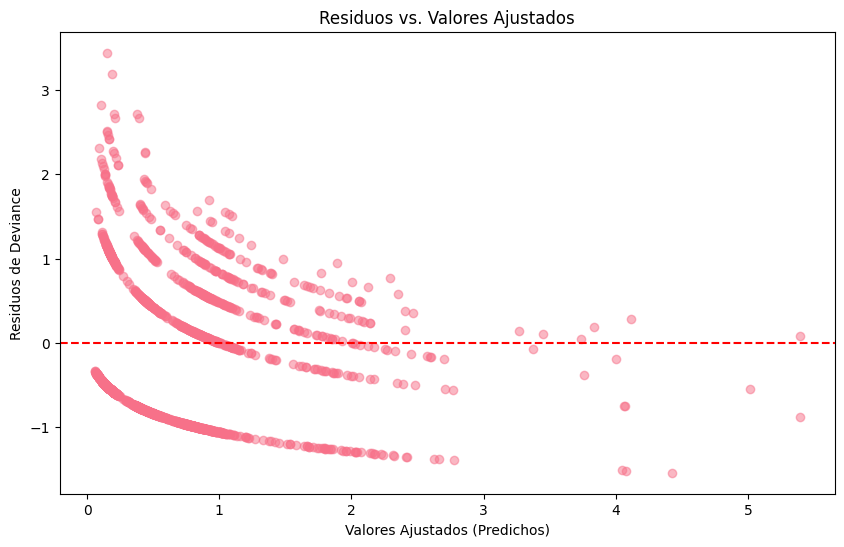

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Obtener valores ajustados (predicciones) y residuos de deviance
fitted_vals = res_nb.mu
resid_deviance = res_nb.resid_deviance

plt.figure(figsize=(10, 6))
plt.scatter(fitted_vals, resid_deviance, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Valores Ajustados (Predichos)')
plt.ylabel('Residuos de Deviance')
plt.title('Residuos vs. Valores Ajustados')
plt.show()

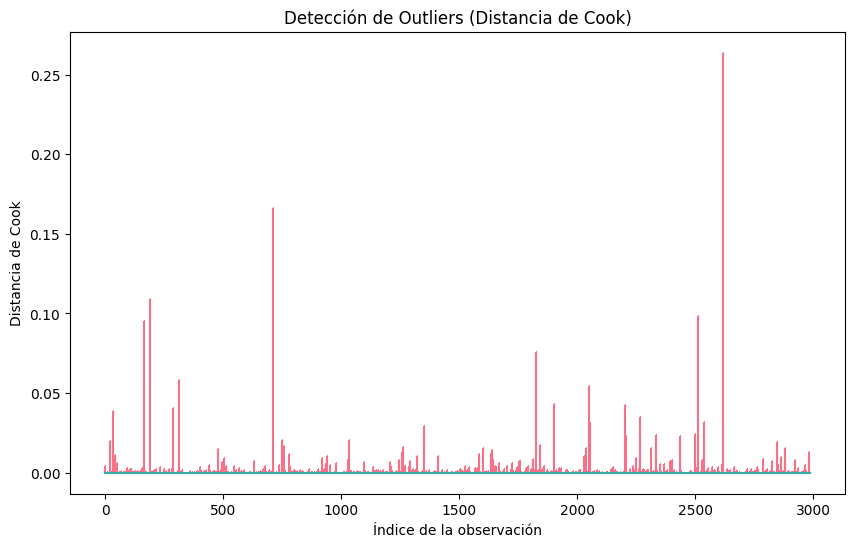

In [ ]:
from statsmodels.stats.outliers_influence import OLSInfluence

# Nota: Aunque se llama OLSInfluence, se puede adaptar o usar get_influence para GLM
# La forma nativa en GLM es:
influence = res_nb.get_influence()

# Graficar la distancia de Cook
(c, p) = influence.cooks_distance
plt.figure(figsize=(10, 6))
plt.stem(np.arange(len(c)), c, markerfmt=",")
plt.xlabel('Índice de la observación')
plt.ylabel('Distancia de Cook')
plt.title('Detección de Outliers (Distancia de Cook)')
plt.show()

In [ ]:
import scipy.stats as stats

print("=== 1. PRUEBA DE BONDAD DE AJUSTE (CHI-CUADRADA) ===")

# Calcular estadístico Chi2 y grados de libertad
chi2_stat = res_nb.pearson_chi2
df_resid = res_nb.df_resid

# Calcular P-value
p_value_chi2 = 1 - stats.chi2.cdf(chi2_stat, df_resid)
dispersion_ratio = chi2_stat / df_resid

print(f"Estadístico Chi2 de Pearson: {chi2_stat:,.2f}")
print(f"Grados de Libertad: {df_resid}")
print(f"Ratio de Dispersión (Chi2/df): {dispersion_ratio:.4f}")
print(f"P-Value: {p_value_chi2:.4f}")

print("\nINTERPRETACIÓN:")
if dispersion_ratio > 1.5:
    print("-> ALERTA: Todavía hay sobredispersión que el modelo no captura.")
elif dispersion_ratio < 0.8:
    print("-> ALERTA: Posible subdispersión (el modelo estima demasiada varianza).")
else:
    print("-> EXCELENTE: El ratio está cerca de 1.0, indicando un buen ajuste de varianza.")

=== 1. PRUEBA DE BONDAD DE AJUSTE (CHI-CUADRADA) ===
Estadístico Chi2 de Pearson: 2,839.40
Grados de Libertad: 2982
Ratio de Dispersión (Chi2/df): 0.9522
P-Value: 0.9691

INTERPRETACIÓN:
-> EXCELENTE: El ratio está cerca de 1.0, indicando un buen ajuste de varianza.


=== GENERANDO MEAN-VARIANCE PLOT ===
Nota: No se encontró alpha explícito, asumiendo 1.0 para visualización
Alpha utilizado para curva teórica: 1.0000


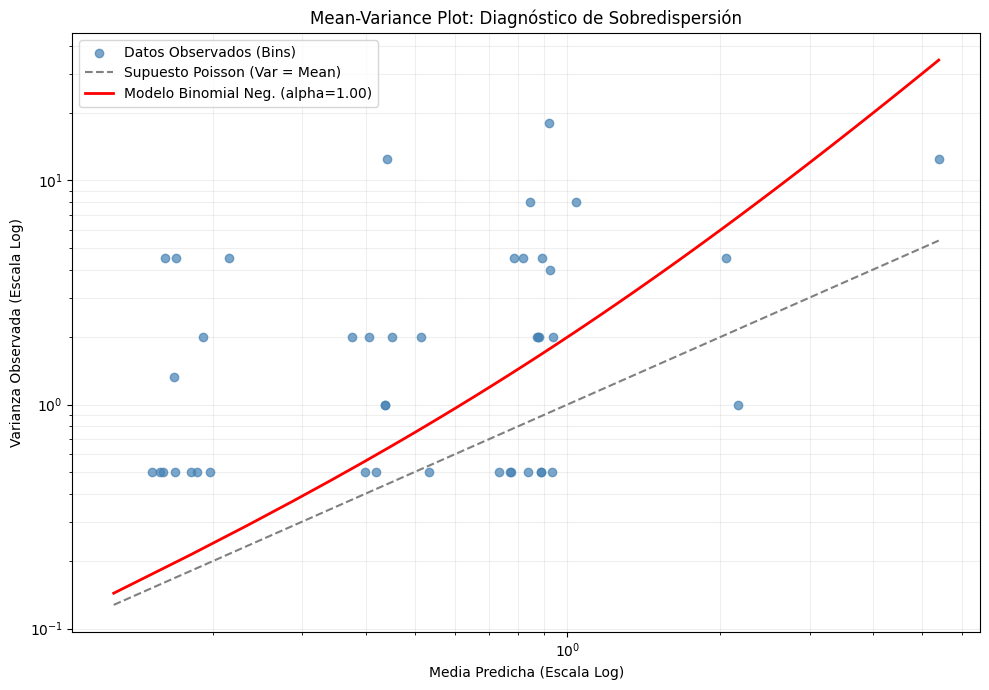

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

def plot_mean_variance(res_nb, y, x, n_bins=5000):
    """
    Genera un gráfico Media-Varianza para diagnosticar sobredispersión.
    Agrupa los datos en bins según su valor predicho.
    """

    print("=== GENERANDO MEAN-VARIANCE PLOT ===")

    # 1. Obtener predicciones (Media estimada mu)
    mu_pred = res_nb.predict(x)

    # 2. Recuperar el parámetro Alpha (dispersión)
    # Statsmodels guarda alpha o ln(alpha) dependiendo de cómo se ajustó
    params = res_nb.params
    if 'alpha' in params:
        alpha = params['alpha']
    elif 'lnalpha' in params:
        alpha = np.exp(params['lnalpha'])
    else:
        # Si usaste GLM con familia fija y no estimó alpha, asumimos el del objeto family
        # Pero idealmente usa el modelo sm.NegativeBinomial para esto
        try:
            alpha = res_nb.model.family.variance.power # Aproximación si no está directo
        except:
            alpha = 1.0 # Fallback
            print("Nota: No se encontró alpha explícito, asumiendo 1.0 para visualización")

    print(f"Alpha utilizado para curva teórica: {alpha:.4f}")

    # 3. Crear Bins para agrupar observaciones similares
    # Necesitamos agrupar para calcular la varianza empírica local
    df_plot = pd.DataFrame({'mu': mu_pred, 'y': y})

    # Usamos qcut para tener número similar de observaciones por punto
    try:
        df_plot['bin'] = pd.qcut(df_plot['mu'], q=n_bins, duplicates='drop')
    except:
        # Fallback a cut si qcut falla por valores repetidos
        df_plot['bin'] = pd.cut(df_plot['mu'], bins=n_bins)

    # 4. Calcular Media y Varianza REAL dentro de cada grupo
    summary = df_plot.groupby('bin')[['y', 'mu']].agg(['mean', 'var'])
    summary.columns = ['y_mean', 'y_var', 'mu_mean', 'mu_var']

    # Limpiar bins con 1 solo dato (varianza NaN)
    summary = summary.dropna()

    # 5. Generar el Gráfico
    plt.figure(figsize=(10, 7))

    # A. Puntos empíricos (Datos reales)
    plt.scatter(summary['mu_mean'], summary['y_var'],
                color='steelblue', alpha=0.7, label='Datos Observados (Bins)', zorder=3)

    # Rango para líneas teóricas
    x_range = np.linspace(summary['mu_mean'].min(), summary['mu_mean'].max(), 100)

    # B. Línea Poisson (Varianza = Media)
    plt.plot(x_range, x_range,
             color='gray', linestyle='--', label='Supuesto Poisson (Var = Mean)', zorder=2)

    # C. Curva Binomial Negativa (Varianza = Media + alpha * Media^2)
    y_nb = x_range + alpha * (x_range**2)
    plt.plot(x_range, y_nb,
             color='red', linewidth=2, label=f'Modelo Binomial Neg. (alpha={alpha:.2f})', zorder=2)

    # Configuración de Ejes (Logarítmica ayuda a ver mejor la dispersión)
    plt.xscale('log')
    plt.yscale('log')

    plt.xlabel('Media Predicha (Escala Log)')
    plt.ylabel('Varianza Observada (Escala Log)')
    plt.title('Mean-Variance Plot: Diagnóstico de Sobredispersión')
    plt.legend()
    plt.grid(True, which="both", ls="-", alpha=0.2)

    plt.tight_layout()
    plt.show()

# --- EJECUTAR LA FUNCIÓN ---
# Asegúrate de pasar tu modelo ajustado (modelo_mle o res_nb)
# Si usas el modelo_mle (el que ajustamos con sm.NegativeBinomial) es mejor porque tiene el alpha exacto.

try:
    # Intenta usar el modelo MLE si lo creaste en el paso anterior
    plot_mean_variance(res_nb, y, X)
except NameError:
    # Si no, usa el modelo GLM que tenías antes
    plot_mean_variance(res_nb, y, X)

=== GENERANDO MEAN-VARIANCE PLOT ===
Nota: No se encontró alpha explícito, asumiendo 1.0
Alpha utilizado para curva teórica: 1.0000


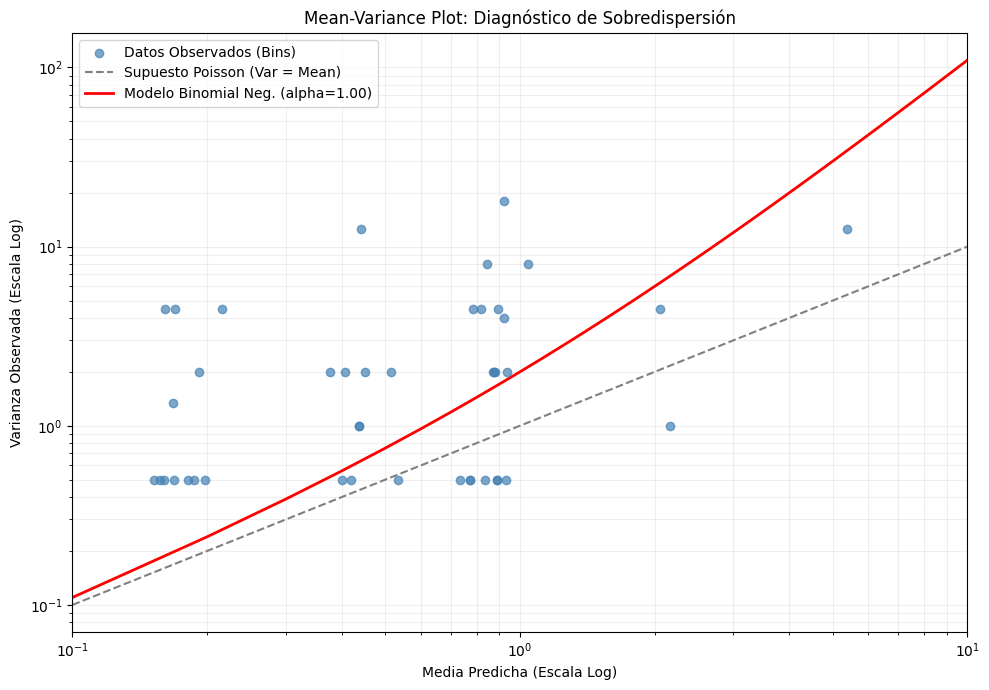

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

# He añadido el parámetro 'x_limits' al final (por defecto es None)
def plot_mean_variance(res_nb, y, x, n_bins=5000, x_limits=None):
    """
    Genera un gráfico Media-Varianza para diagnosticar sobredispersión.
    x_limits: Tupla opcional (min, max) para recortar el eje X. Ej: (0.01, 5)
    """

    print("=== GENERANDO MEAN-VARIANCE PLOT ===")

    # 1. Obtener predicciones
    mu_pred = res_nb.predict(x)

    # 2. Recuperar el parámetro Alpha
    params = res_nb.params
    if 'alpha' in params:
        alpha = params['alpha']
    elif 'lnalpha' in params:
        alpha = np.exp(params['lnalpha'])
    else:
        try:
            alpha = res_nb.model.family.variance.power
        except:
            alpha = 1.0
            print("Nota: No se encontró alpha explícito, asumiendo 1.0")

    print(f"Alpha utilizado para curva teórica: {alpha:.4f}")

    # 3. Crear Bins
    df_plot = pd.DataFrame({'mu': mu_pred, 'y': y})

    try:
        df_plot['bin'] = pd.qcut(df_plot['mu'], q=n_bins, duplicates='drop')
    except:
        df_plot['bin'] = pd.cut(df_plot['mu'], bins=n_bins)

    # 4. Calcular Media y Varianza REAL
    summary = df_plot.groupby('bin')[['y', 'mu']].agg(['mean', 'var'])
    summary.columns = ['y_mean', 'y_var', 'mu_mean', 'mu_var']
    summary = summary.dropna()

    # 5. Generar el Gráfico
    plt.figure(figsize=(10, 7))

    # A. Puntos empíricos
    plt.scatter(summary['mu_mean'], summary['y_var'],
                color='steelblue', alpha=0.7, label='Datos Observados (Bins)', zorder=3)

    # Rango para líneas teóricas (dinámico según los datos o los límites)
    # Si definimos límites, ajustamos la curva teórica para que se vea bien en ese rango
    if x_limits:
        x_min, x_max = x_limits
    else:
        x_min, x_max = summary['mu_mean'].min(), summary['mu_mean'].max()

    x_range = np.linspace(x_min, x_max, 100)

    # B. Línea Poisson
    plt.plot(x_range, x_range,
             color='gray', linestyle='--', label='Supuesto Poisson (Var = Mean)', zorder=2)

    # C. Curva Binomial Negativa
    y_nb = x_range + alpha * (x_range**2)
    plt.plot(x_range, y_nb,
             color='red', linewidth=2, label=f'Modelo Binomial Neg. (alpha={alpha:.2f})', zorder=2)

    plt.xscale('log')
    plt.yscale('log')

    # --- AQUÍ SE APLICA EL RECORTE ---
    if x_limits is not None:
        plt.xlim(x_limits)
    # ---------------------------------

    plt.xlabel('Media Predicha (Escala Log)')
    plt.ylabel('Varianza Observada (Escala Log)')
    plt.title('Mean-Variance Plot: Diagnóstico de Sobredispersión')
    plt.legend()
    plt.grid(True, which="both", ls="-", alpha=0.2)

    plt.tight_layout()
    plt.show()

# --- CÓMO EJECUTARLO ---

# Opción 1: Automático (como antes)
# plot_mean_variance(res_nb, y, X)

# Opción 2: RECORTANDO EL EJE X
# Como es escala logarítmica, el primer número debe ser mayor que 0 (ej. 0.01 o 0.1)
# Ajusta los valores (inicio, fin) según lo que necesites ver
try:
    plot_mean_variance(res_nb, y, X, x_limits=(0.1, 10))
except NameError:
    print("Asegúrate de tener definidos res_nb, y, X")

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.stats import nbinom, norm

def diagnosticos_avanzados_conteo(res_nb, y, x):
    """
    Genera:
    1. Randomized Quantile Residuals (Q-Q Plot)
    2. Hanging Rootogram
    3. Gráfico de Frecuencias Obs vs Pred
    """

    print("=== GENERANDO DIAGNÓSTICOS AVANZADOS ===")

    # 1. OBTENER PARÁMETROS (Mu y Alpha)
    mu = res_nb.predict(x)

    # Extracción robusta de Alpha (funciona para GLM y MLE)
    params = res_nb.params
    if 'alpha' in params:
        alpha = params['alpha']
    elif 'lnalpha' in params:
        alpha = np.exp(params['lnalpha'])
    else:
        # Fallback para GLM si no se encuentra explícito
        try: alpha = res_nb.model.family.variance.power
        except: alpha = 1.0

    print(f"Parámetro Alpha detectado: {alpha:.4f}")

    # Convertir parámetros de Statsmodels (mu, alpha) a Scipy (n, p)
    # NB2: Var = mu + alpha * mu^2
    # Scipy n = 1/alpha, p = 1/(1+alpha*mu)
    n_scipy = 1.0 / alpha
    p_scipy = 1.0 / (1.0 + alpha * mu)

    # =================================================================
    # GRAFICO 1: RANDOMIZED QUANTILE RESIDUALS (RQR)
    # =================================================================
    # La magia: suavizamos la distribución discreta añadiendo ruido uniforme
    # entre los escalones de la CDF

    # Calcular límites de la CDF para cada observación
    cdf_low = nbinom.cdf(y - 1, n_scipy, p_scipy)
    cdf_high = nbinom.cdf(y, n_scipy, p_scipy)

    # Generar valor uniforme aleatorio entre esos límites
    u = np.random.uniform(cdf_low, cdf_high)

    # Transformar a la inversa normal estándar
    rqr = norm.ppf(u)

    # Evitar infinitos (casos extremos numéricos)
    rqr = rqr[np.isfinite(rqr)]

    # =================================================================
    # GRAFICO 2 & 3: PREPARACIÓN DE DATOS PARA ROOTOGRAMA Y FRECUENCIAS
    # =================================================================
    max_count = int(y.max())
    # Cortamos en un valor razonable para visualización (ej. percentil 99 o fijo)
    limit_x = min(max_count, 10)

    counts_obs = y.value_counts().sort_index()
    counts_obs = counts_obs.reindex(range(limit_x + 1), fill_value=0)

    # Calcular conteos esperados sumando probabilidades
    counts_exp = []
    for k in range(limit_x + 1):
        # Probabilidad de que cada individuo tenga k seguros
        prob_k = nbinom.pmf(k, n_scipy, p_scipy)
        counts_exp.append(prob_k.sum()) # Suma de probs = frecuencia esperada

    counts_exp = np.array(counts_exp)

    # =================================================================
    # PLOTEO
    # =================================================================
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # --- 1. Q-Q Plot de RQR ---
    stats.probplot(rqr, dist="norm", plot=axes[0])
    axes[0].set_title("1. Randomized Quantile Residuals (Q-Q)", fontsize=12, fontweight='bold')
    axes[0].set_xlabel("Cuantiles Teóricos (Normal)")
    axes[0].set_ylabel("Cuantiles de Residuos")
    axes[0].get_lines()[0].set_markerfacecolor('steelblue')
    axes[0].get_lines()[0].set_alpha(0.5)
    axes[0].grid(True, alpha=0.3)

    # --- 2. Hanging Rootogram ---
    # En un Rootogram, graficamos la raíz cuadrada de las frecuencias
    # Las barras cuelgan de la curva teórica roja.
    # Si el ajuste es bueno, la base de las barras debe estar en cero.

    x_vals = np.arange(limit_x + 1)
    obs_sqrt = np.sqrt(counts_obs)
    exp_sqrt = np.sqrt(counts_exp)

    # La barra "cuelga" desde la esperada hacia abajo hasta la observada
    # Top = Expected, Bottom = Expected - Observed
    axes[1].bar(x_vals, obs_sqrt, bottom=exp_sqrt - obs_sqrt,
                color='lightgray', edgecolor='gray', alpha=0.8, width=0.6)

    # Línea de referencia (lo esperado)
    axes[1].plot(x_vals, exp_sqrt, 'r-', lw=2, marker='o', label='Esperado (Raíz)')
    axes[1].axhline(0, color='black', lw=1)

    axes[1].set_title("2. Hanging Rootogram", fontsize=12, fontweight='bold')
    axes[1].set_xlabel("Número de Seguros")
    axes[1].set_ylabel("Raíz Cuadrada de Frecuencia")
    axes[1].legend()

    # --- 3. Frecuencias Observadas vs Predichas ---
    width = 0.35
    axes[2].bar(x_vals - width/2, counts_obs, width, label='Observado', color='steelblue')
    axes[2].bar(x_vals + width/2, counts_exp, width, label='Predicho (Modelo)', color='darkred')

    axes[2].set_title("3. Obs. vs Predichas (Conteo Real)", fontsize=12, fontweight='bold')
    axes[2].set_xlabel("Número de Seguros")
    axes[2].set_ylabel("Cantidad de Hogares")
    axes[2].legend()

    plt.tight_layout()
    plt.show()



=== GENERANDO DIAGNÓSTICOS AVANZADOS ===
Parámetro Alpha detectado: 1.0000


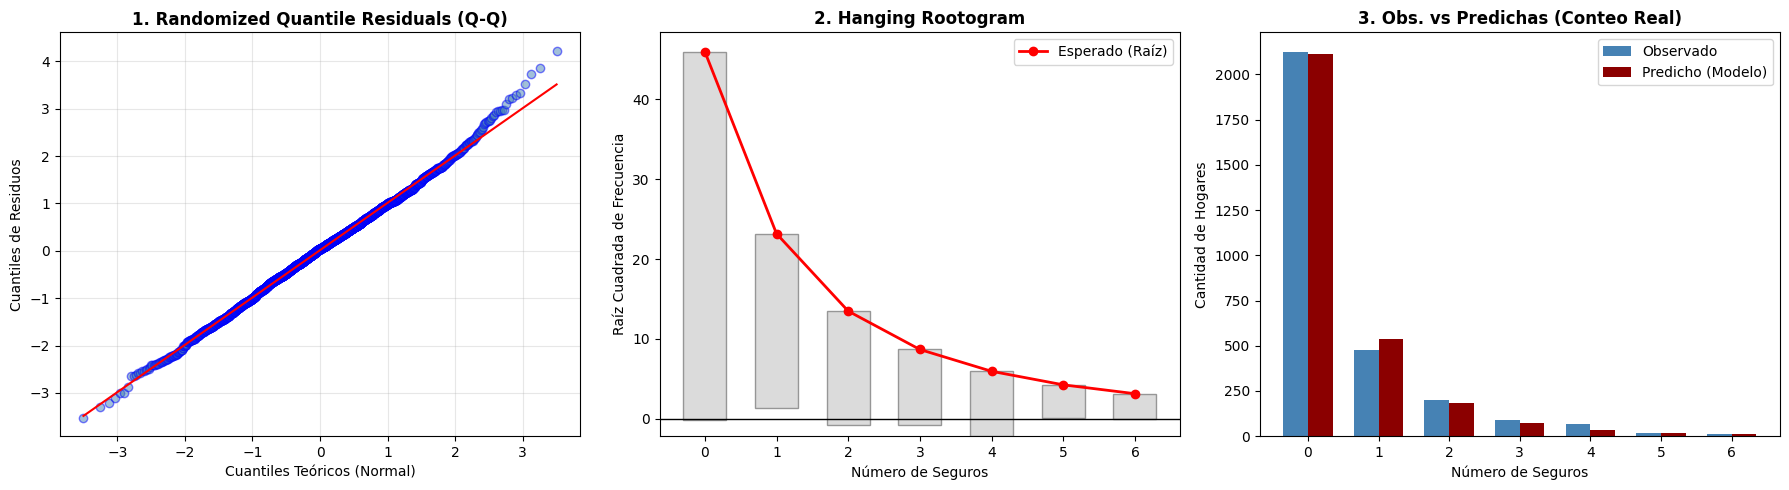

In [ ]:
    diagnosticos_avanzados_conteo(res_nb, y, X)